<a href="https://colab.research.google.com/github/AKAAKS/swim_analyisis/blob/main/sequence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# classifiers and metrics imports
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.notebook import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

russian_labels = [
    "Batterfly",
    "Bras",
    "Kroli na grudi L",
    "Kroli na grudi R",
    "Kroli na spine L",
    "Kroli na spine R",
    "Kuvirok",
    "Ottalkivanie",
    "Povorot",
    "Prijki (tumba)"
]

english_translations = [
    "Butterfly stroke",
    "Breaststroke",
    "Freestyle: L",
    "Freestyle: R",
    "Backstroke: L",
    "Backstroke: R",
    "Somersault",
    "Push-off",
    "Turn",
    "Dive start"
]


In [18]:
SEQUENCE_LENGTH = 256  # change this value as needed
main_folder = "/content/drive/MyDrive/SwimVid/Code/archive"  # Change this to the path where your data is stored
data_records = []
labels = []

In [19]:
def flatten_window(df: pd.DataFrame, seq_len: int) -> pd.Series:
    """
    Given a DataFrame of shape (n_timesteps, n_features),
    pad or truncate to exactly seq_len rows, then flatten into a 1D feature vector.
    """
    arr = df.values
    n_rows, n_feats = arr.shape
    if n_rows < seq_len:
        # pad with zeros at the end
        pad = np.zeros((seq_len - n_rows, n_feats))
        arr = np.vstack([arr, pad])
    else:
        arr = arr[:seq_len]
    # flatten row-major (time-major)
    flat = arr.flatten()
    # build column names: feat_timestep
    cols = [f"{feat}_{t}" for t in range(seq_len) for feat in df.columns]
    return pd.Series(flat, index=cols)

for root, dirs, files in os.walk(main_folder, topdown=False):
    for style_dir in dirs:
        style_label = style_dir[2:].strip()  # remove leading folder number and space
        style_path = os.path.join(root, style_dir)
        for _, _, file_list in os.walk(style_path):
            for filename in file_list:
                file_path = os.path.join(style_path, filename)
                # read IMU data
                df = pd.read_csv(file_path)
                # drop timestamp column if present
                if "hh:mm:ss.ms" in df.columns:
                    df = df.drop(["hh:mm:ss.ms"], axis=1)
                # rename sensor columns
                df = df.rename(columns={
                    'gyroX[mdps]': 'gyroX', 'gyroY[mdps]': 'gyroY', 'gyroZ[mdps]': 'gyroZ',
                    'accX[mg]': 'accX',    'accY[mg]': 'accY',    'accZ[mg]': 'accZ',
                    'magX[mG]': 'magX',    'magY[mG]': 'magY',    'magZ[mG]': 'magZ'
                })
                # split into windows of length SEQUENCE_LENGTH
                total_rows = len(df)
                num_windows = int(np.ceil(total_rows / SEQUENCE_LENGTH))
                for w in range(num_windows):
                    start = w * SEQUENCE_LENGTH
                    end = start + SEQUENCE_LENGTH
                    window_df = df.iloc[start:end]
                    # flatten + pad/truncate window
                    sample = flatten_window(window_df, SEQUENCE_LENGTH)
                    data_records.append(sample)
                    labels.append(style_label)

In [20]:
# assemble into DataFrame
data = pd.DataFrame(data_records)
# add label column
data['name'] = labels

# --- Encode labels as integers ---
le = LabelEncoder()
data['label'] = le.fit_transform(data['name'])

# --- Prepare features and target ---
X = data.drop(['name', 'label'], axis=1)
y = data['label']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=33, stratify=y
)

In [21]:
print(X_train.shape)
data.head()

(600, 2304)


,gyroX_0,gyroY_0,gyroZ_0,accX_0,accY_0,accZ_0,magX_0,magY_0,magZ_0,gyroX_1,...,gyroY_255,gyroZ_255,accX_255,accY_255,accZ_255,magX_255,magY_255,magZ_255,name,label
0,-44.0,127.0,-177.0,-1432.0,-16.0,-244.0,526.0,-334.0,472.0,-33.0,...,-45.0,179.0,-595.0,189.0,-98.0,489.0,-210.0,489.0,Bras,1
1,-92.0,-34.0,175.0,-573.0,155.0,-110.0,489.0,-210.0,489.0,-92.0,...,-144.0,108.0,-754.0,699.0,-292.0,441.0,-207.0,501.0,Bras,1
2,268.0,-186.0,205.0,-779.0,698.0,-271.0,439.0,-193.0,490.0,268.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bras,1
3,-132.0,-36.0,305.0,-997.0,33.0,-189.0,636.0,-355.0,-21.0,-131.0,...,-135.0,366.0,-732.0,242.0,-204.0,649.0,-339.0,16.0,Bras,1
4,-166.0,-130.0,362.0,-761.0,224.0,-214.0,649.0,-339.0,16.0,-167.0,...,-278.0,469.0,-394.0,225.0,-206.0,655.0,-310.0,87.0,Bras,1


ML Models

In [22]:
# --- Model testing with new dataset ---
models = {
    "LinearSVC": LinearSVC(max_iter=5000),
    "KNN": KNeighborsClassifier(),
    "SVC": SVC(),
    "LogisticRegression": LogisticRegression(max_iter=5000),
    "RandomForestClassifier": RandomForestClassifier(),
    "XGBoost": xgb.XGBClassifier(eval_metric='mlogloss')
}

results = {}
for model_name, model in models.items():
    # Train
    model.fit(X_train, y_train)
    # Validation accuracy
    acc = model.score(X_val, y_val)
    results[model_name] = acc
    print(" ==================================")
    print(f"{model_name}: {acc:.4f}")
    # Detailed report
    y_pred = model.predict(X_val)
    print(classification_report(y_val, y_pred, target_names=le.classes_))
    # print(confusion_matrix(y_val, y_pred))




/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC: 0.6434
                  precision    recall  f1-score   support

       Batterfly       0.71      0.47      0.57        32
            Bras       0.97      0.97      0.97        32
Kroli na grudi L       0.65      0.80      0.72        30
Kroli na grudi R       0.42      0.73      0.54        30
Kroli na spine L       0.58      0.61      0.60        23
Kroli na spine R       0.41      0.57      0.47        23
         Kuvirok       0.92      0.79      0.85        14
    Ottalkivanie       0.72      0.54      0.62        39
         Povorot       0.69      0.43      0.53        21
 Prijki( .tumba)       1.00      0.43      0.60        14

        accuracy                           0.64       258
       macro avg       0.71      0.63      0.64       258
    weighted avg       0.69      0.64      0.65       258

KNN: 0.7752
                  precision    recall  f1-score   support

       Batterfly       0.87      0.84      0.86        32
            Bras       0.84      0.97 

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression: 0.7442
                  precision    recall  f1-score   support

       Batterfly       0.77      0.62      0.69        32
            Bras       0.93      0.88      0.90        32
Kroli na grudi L       0.79      0.87      0.83        30
Kroli na grudi R       0.75      0.80      0.77        30
Kroli na spine L       0.54      0.61      0.57        23
Kroli na spine R       0.57      0.57      0.57        23
         Kuvirok       0.80      0.86      0.83        14
    Ottalkivanie       0.69      0.74      0.72        39
         Povorot       0.88      0.71      0.79        21
 Prijki( .tumba)       0.79      0.79      0.79        14

        accuracy                           0.74       258
       macro avg       0.75      0.74      0.74       258
    weighted avg       0.75      0.74      0.74       258

RandomForestClassifier: 0.8450
                  precision    recall  f1-score   support

       Batterfly       0.89      0.97      0.93        32
          

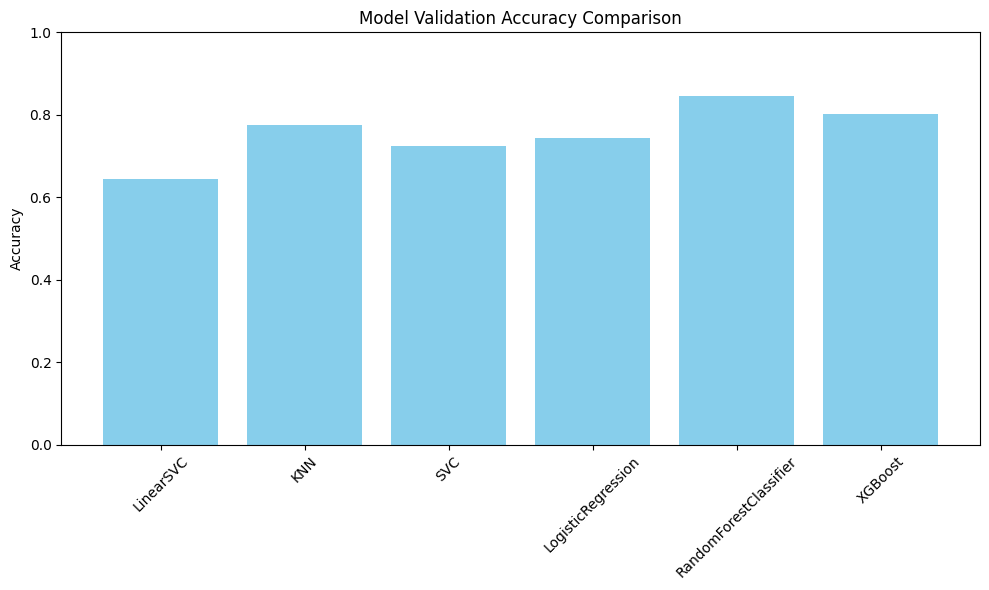

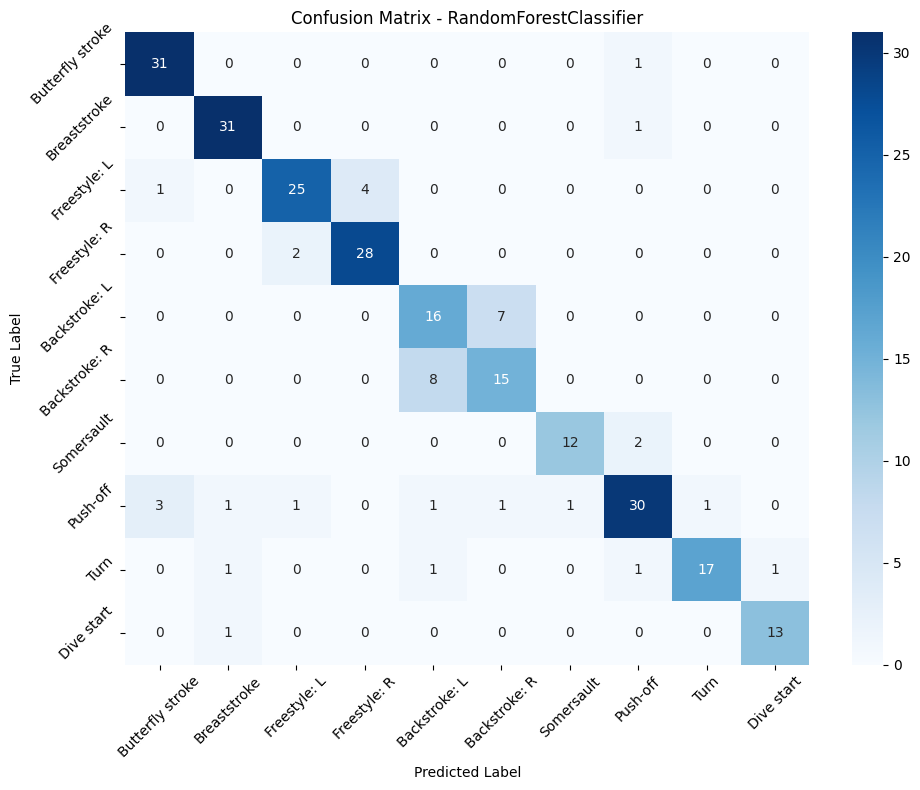

In [23]:
# --- Visualization of model performance ---
# Bar chart of validation accuracies
plt.figure(figsize=(10, 6))
plt.bar(results.keys(), results.values(), color='skyblue')
plt.title("Model Validation Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Confusion matrix heatmap for best model
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]
y_best_pred = best_model.predict(X_val)
cm = confusion_matrix(y_val, y_best_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=english_translations, yticklabels=english_translations, cmap='Blues')
plt.title(f"Confusion Matrix - {best_model_name}")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.tight_layout()
plt.show()


Deep Learning

In [24]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from scipy.signal import butter, filtfilt

In [27]:
SEQUENCE_LENGTH = 256      # window length (timesteps)
STEP_SIZE       = 160      # sliding window step
LOWPASS_CUTOFF  = 10       # Hz for low-pass filter
DOWN_FREQ       = '4ms'   # downsampling interval
PATIENCE        = 100
BATCH_SIZE      = 16
NUM_EPOCHS      = 1000
LEARNING_RATE   = 1e-4
WEIGHT_DECAY    = 1e-3
CNN_CHANNELS    = 64
NUM_RES_BLOCKS  = 4
HIDDEN_DIM      = 64
NUM_LAYERS      = 3
DROPOUT_RATE    = 0.3
DEVICE          = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_PATH       = "/content/drive/MyDrive/SwimVid/Code/archive"

In [28]:
SENSOR_COLS = [
    'gyroX[mdps]','gyroY[mdps]','gyroZ[mdps]',
    'accX[mg]','accY[mg]','accZ[mg]',
    'magX[mG]','magY[mG]','magZ[mG]'
]

# --- Signal processing utilities ---

def lowpass(data, cutoff, fs, order=2):
    nyq = 0.5 * fs
    b, a = butter(order, cutoff/nyq, btype='low')
    return filtfilt(b, a, data)


def load_and_preprocess(main_folder, seq_len, step):
    X, y = [], []
    for root, dirs, _ in os.walk(main_folder):
        for style_dir in dirs:
            label = style_dir[2:].strip()
            dir_path = os.path.join(root, style_dir)
            for fn in os.listdir(dir_path):
                path = os.path.join(dir_path, fn)
                # 1. Load & timestamp
                df = pd.read_csv(path)
                df['timestamp'] = pd.to_datetime(df['hh:mm:ss.ms'], format='%H:%M:%S.%f')
                df.set_index('timestamp', inplace=True)
                # Estimate sampling rate
                dt = df.index.to_series().diff().dt.total_seconds().dropna()
                fs = 1.0 / dt.mean()
                # 2. Low-pass filter all channels
                df_f = df.copy()
                for ch in SENSOR_COLS:
                    df_f[ch] = lowpass(df[ch].values, LOWPASS_CUTOFF, fs)
                # 3. Downsample and interpolate
                df_ds = df_f.resample(DOWN_FREQ).asfreq()
                df_ds = df_ds.interpolate(method='time')
                df_ds = df_ds.ffill().bfill()
                arr = df_ds[SENSOR_COLS].values  # shape (n_timesteps, n_feats)
                n = arr.shape[0]
                # sliding windows with overlap
                if n < seq_len:
                    # pad single short window
                    pad = np.zeros((seq_len - n, arr.shape[1]))
                    window = np.vstack([arr, pad])
                    X.append(window); y.append(label)
                else:
                    # generate windows stepping by 'step'
                    for start in range(0, n - seq_len + 1, step):
                        window = arr[start:start + seq_len]
                        X.append(window); y.append(label)
                    # include final window ensuring coverage
                    if (n - seq_len) % step != 0:
                        window = arr[-seq_len:]
                        X.append(window); y.append(label)
    return np.array(X), np.array(y)

X_seq, y_raw = load_and_preprocess(DATA_PATH, SEQUENCE_LENGTH, STEP_SIZE)
le = LabelEncoder()
y = le.fit_transform(y_raw)
X_train, X_val, y_train, y_val = train_test_split(
    X_seq, y, test_size=0.3, random_state=42, stratify=y
)


In [29]:
X_train.shape

(869, 256, 9)

In [30]:
class IMUDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

train_loader = DataLoader(IMUDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(IMUDataset(X_val,   y_val),   batch_size=BATCH_SIZE)


In [31]:
class ResidualBlock1D(nn.Module):
    def __init__(self, channels, dropout):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, channels, 3, padding=1)
        self.bn1   = nn.BatchNorm1d(channels)
        self.relu  = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv1d(channels, channels, 3, padding=1)
        self.bn2   = nn.BatchNorm1d(channels)
    def forward(self, x):
        res = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.dropout(out)
        out = self.bn2(self.conv2(out))
        return self.relu(out + res)

class ResCNN_BiLSTM(nn.Module):
    def __init__(self, in_dim, cnn_ch, res_blocks, hid_dim,
                 n_layers, n_classes, dropout):
        super().__init__()
        self.conv_in = nn.Conv1d(in_dim, cnn_ch, 5, padding=2)
        self.bn_in   = nn.BatchNorm1d(cnn_ch)
        self.relu    = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.resblocks = nn.Sequential(*[
            ResidualBlock1D(cnn_ch, dropout) for _ in range(res_blocks)
        ])
        self.lstm = nn.LSTM(cnn_ch, hid_dim, n_layers,
                            batch_first=True, dropout=dropout,
                            bidirectional=True)
        self.fc1 = nn.Linear(hid_dim*2, hid_dim)
        self.fc2 = nn.Linear(hid_dim, 16)
        self.fc3 = nn.Linear(16, n_classes)
    def forward(self, x):
        x = x.permute(0,2,1)  # [B, F, T]
        x = self.relu(self.bn_in(self.conv_in(x)))
        x = self.resblocks(x); x = self.dropout(x)
        x = x.permute(0,2,1)  # [B, T, cnn_ch]
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.relu(self.fc1(out)); out = self.dropout(out)
        out = self.relu(self.fc2(out));
        return self.fc3(out)

In [32]:
model = ResCNN_BiLSTM(
    in_dim=X_train.shape[2], cnn_ch=CNN_CHANNELS,
    res_blocks=NUM_RES_BLOCKS, hid_dim=HIDDEN_DIM,
    n_layers=NUM_LAYERS, n_classes=len(le.classes_),
    dropout=DROPOUT_RATE
).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=15)

best_val_loss = float('inf'); epochs_no_improve = 0
epoch_bar = trange(1, NUM_EPOCHS+1, desc='Epochs')
for epoch in epoch_bar:
    # train loop
    model.train()
    tloss=tacc=0
    for Xb,yb in train_loader:
        Xb,yb = Xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(); out=model(Xb); loss=criterion(out,yb)
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),2.0); optimizer.step()
        tloss += loss.item()*Xb.size(0)
        tacc += (out.argmax(1)==yb).sum().item()
    tr_loss, tr_acc = tloss/len(train_loader.dataset), tacc/len(train_loader.dataset)
    # val loop
    model.eval(); vloss=vacc=0
    with torch.no_grad():
        for Xb,yb in val_loader:
            Xb,yb = Xb.to(DEVICE), yb.to(DEVICE)
            out=model(Xb); loss=criterion(out,yb)
            vloss += loss.item()*Xb.size(0)
            vacc += (out.argmax(1)==yb).sum().item()
    val_loss, val_acc = vloss/len(val_loader.dataset), vacc/len(val_loader.dataset)
    scheduler.step(val_loss)
    if val_loss < best_val_loss:
        best_val_loss, epochs_no_improve = val_loss, 0; best_state = model.state_dict()
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            epoch_bar.write(f"Early stopping at epoch {epoch}"); break
    epoch_bar.set_postfix({'t_loss':f"{tr_loss:.3f}",'t_acc':f"{tr_acc:.3f}",'v_loss':f"{val_loss:.3f}",'v_acc':f"{val_acc:.3f}"})

# load/save best
model.load_state_dict(best_state)
torch.save(best_state,'best_ResCNNBILSTM.pth')


Epochs:   0%|          | 0/1000 [00:00<?, ?it/s]

Early stopping at epoch 208


In [33]:
from sklearn.metrics import classification_report
model.eval(); preds, labs = [], []
with torch.no_grad():
    for Xb,yb in val_loader:
        out=model(Xb.to(DEVICE)).argmax(1).cpu().numpy()
        preds.extend(out); labs.extend(yb.numpy())
print(classification_report(labs, preds, target_names=english_translations))

                  precision    recall  f1-score   support

Butterfly stroke       0.93      0.93      0.93        42
    Breaststroke       0.91      0.98      0.94        42
    Freestyle: L       0.58      0.80      0.67        40
    Freestyle: R       0.59      0.50      0.54        40
   Backstroke: L       0.33      0.03      0.06        31
   Backstroke: R       0.47      0.97      0.63        31
      Somersault       0.88      0.92      0.90        24
        Push-off       0.80      0.63      0.71        65
            Turn       0.74      0.68      0.71        34
      Dive start       1.00      0.96      0.98        24

        accuracy                           0.73       373
       macro avg       0.72      0.74      0.71       373
    weighted avg       0.73      0.73      0.71       373



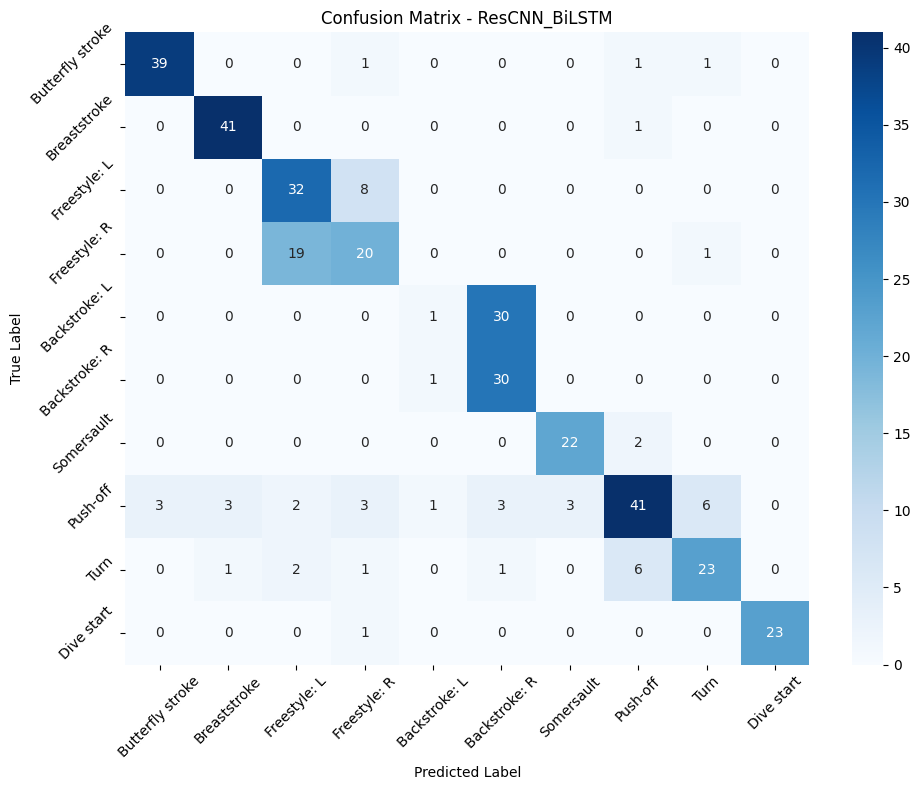

In [34]:
cm = confusion_matrix(labs, preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=english_translations, yticklabels=english_translations, cmap='Blues')
plt.title(f"Confusion Matrix - ResCNN_BiLSTM")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.tight_layout()
plt.show()